# Defensive-line get-off, development only

Fits the protocol in `reports/getoff_v1_protocol.md` on 2023–24. The 2025 class is not read. This notebook does not reopen the closed receiver-cut study.


In [1]:
from pathlib import Path
import json
import os
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "config" / "getoff_v1.yaml").exists():
    for parent in [ROOT, *ROOT.parents]:
        if (parent / "config" / "getoff_v1.yaml").exists():
            os.chdir(parent)
            ROOT = parent
            break
sys.path.insert(0, str(ROOT / "src"))
os.environ["PYTHONPATH"] = str(ROOT / "src") + os.pathsep + os.environ.get("PYTHONPATH", "")
from bdb2027.getoff import run
summary = run(ROOT)
print("primary players", summary["quality"]["primary_players"])
print("2024 MAE", summary["chronological_mae"])
print("M2-M1", summary["delta_m2_minus_m1"], summary["delta_bootstrap"])
print("nested", summary["nested_loo_mae"])
print("transit coefficient", summary["standardized_coefficients_2023"].get("early_transit_1_5_s"))


{
  "stopped_before_models": false,
  "quality": {
    "attempts": 94,
    "valid_attempts": 94,
    "valid_fraction": 1.0,
    "ambiguous_start": 0,
    "incomplete_crossing": 0,
    "players_with_8_getoff": 40,
    "primary_players": 37,
    "repeatability": {
      "players_with_two_valid_attempts": 44,
      "mean_second_minus_first": 0.0068036460401167675,
      "sd_second_minus_first": 0.03519860821038311,
      "icc": {
        "n_players": 44,
        "n_attempts": 88,
        "icc": 0.5932677666770224,
        "within_sd": 0.0250706386656444,
        "sd_of_player_means": 0.03508653563593099,
        "latent_between_sd": 0.03027864794504212,
        "n0": 2.0
      },
      "median_abs_change_when_origin_moves_0_25_forward": 0.03246753184769774
    }
  },
  "n_2023": 18,
  "n_2024": 19,
  "alphas": {
    "M0": 0.3,
    "M1": 1.0,
    "M2": 3.0
  },
  "chronological_mae": {
    "M0": 0.05834019133922743,
    "M1": 0.06749967516486115,
    "M2": 0.060708870823966136
  },
  "delt

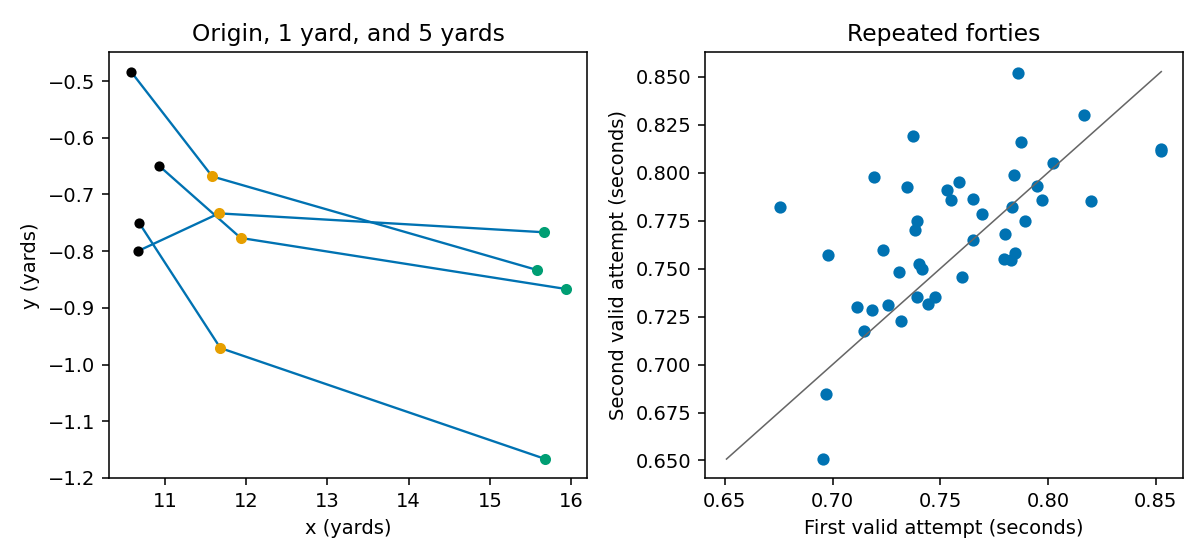

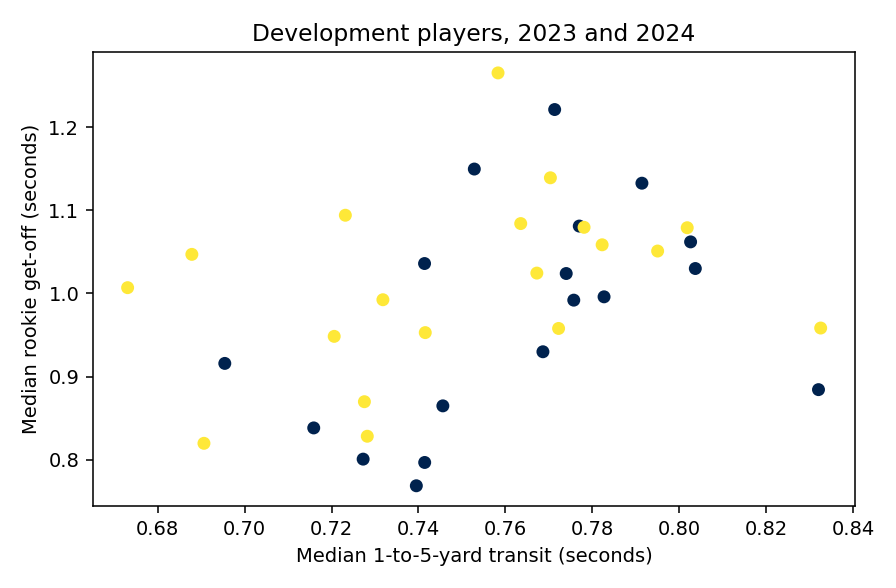

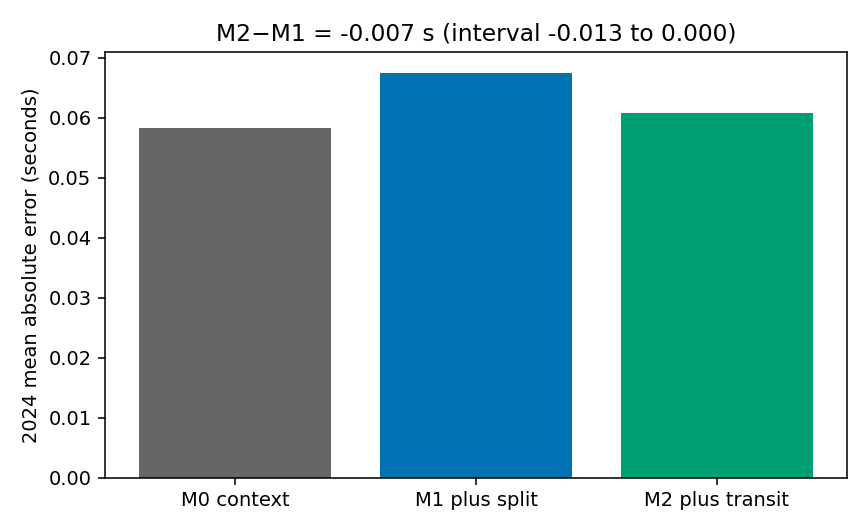

In [2]:
from IPython.display import Image, display
for name in ["fig_repeats.png", "fig_translation.png", "fig_prediction.png"]:
    display(Image(filename=f"outputs/getoff_v1/{name}"))
